# SaaS Customer Churn Prediction — Optimized Deep Learning Classification

# Mini Project Overview

### General Details

**Date:** 12-09-2026

**Student Name:** Gautham VR

**Batch / Cohort:** April-October (Afternoon)

**Project Title:** SaaS Customer Churn Prediction Using Deep Learning

**Project Type:** Binary Classification

---

### Tools, Libraries & Frameworks Used

**Programming Language:** Python

**Data Manipulation & Analysis:** Pandas, NumPy

**Data Visualization:** Matplotlib, Seaborn

**Machine Learning:** Scikit-Learn (Logistic Regression, Stratified Cross-Validation, Model Evaluation)

**Deep Learning:** TensorFlow, Keras (Feedforward Neural Network / Multi-Layer Perceptron)

**Data Preprocessing:** Scikit-Learn Pipeline, ColumnTransformer, SimpleImputer, MinMaxScaler, OneHotEncoder

**Model Persistence:** Joblib, Keras Model Saving

**Environment / Tools:** Jupyter Notebook, VS Code, Git, GitHub

---

### Project Breakdown & Execution

**What I Worked On:**

Developed a SaaS Customer Churn Prediction system using customer account information, usage logs, and support-ticket records. The objective was to predict whether a customer account is likely to churn (Yes/No).

The project involved customer-level feature engineering, data quality assessment, exploratory data analysis, missing value handling, categorical encoding, numerical scaling, and model development.

A Feedforward Neural Network (MLP) with multiple hidden layers, ReLU activation, Batch Normalization, Dropout, and a Sigmoid output layer was implemented using TensorFlow/Keras.

The Deep Learning model was evaluated against a Balanced Logistic Regression baseline using Stratified 5-Fold Cross-Validation and Out-of-Fold predictions.

**What I Completed:**

* Data Loading & Data Quality Checking
* Data Inspection and Missing Value Analysis
* Data Cleaning and Feature Engineering
* Customer-level Usage Log Aggregation
* Customer-level Support Ticket Aggregation
* Exploratory Data Analysis (EDA)
* Missing Value Imputation
* Categorical Feature Encoding
* Numerical Feature Scaling
* Class Imbalance Handling using Balanced Class Weights
* Logistic Regression Model Development
* Deep Learning Model Development (MLP)
* Neural Network Regularization using Dropout and L2
* Batch Normalization
* Early Stopping and Learning Rate Reduction
* Stratified 5-Fold Cross-Validation
* Out-of-Fold Prediction Generation
* Probability Threshold Optimization
* Logistic Regression vs Deep Learning Comparison
* Model Evaluation using Accuracy, Precision, Recall, F1-Score, ROC-AUC and PR-AUC
* Confusion Matrix Analysis
* ROC and Precision-Recall Curve Visualization
* Feature Importance Analysis
* Final Model Selection
* Final Churn Prediction for 74 Customer Accounts
* Model and Preprocessing Pipeline Saving

---

### Challenges & Solutions

**Blocker / Challenge 1: The dataset contained imbalanced churn and non-churn classes.**

**How I Addressed It:**

Identified the class distribution and used balanced class weights during Logistic Regression and Neural Network training. Evaluated model performance using Precision, Recall, F1-Score, ROC-AUC, and PR-AUC instead of relying only on accuracy.

**Blocker / Challenge 2: Multiple customer data sources needed to be combined.**

**How I Addressed It:**

Performed data quality checks and integrated account master data, usage logs, and support-ticket information using `account_id`. Aggregated multiple usage and support records into customer-level features.

**Blocker / Challenge 3: Missing values and invalid login activity affected data preparation.**

**How I Addressed It:**

Investigated missing values across datasets, converted invalid negative login counts into missing values, and implemented median and most-frequent imputation through Scikit-Learn preprocessing pipelines.

**Blocker / Challenge 4: Deep Learning performance needed to be compared fairly against a traditional Machine Learning model.**

**How I Addressed It:**

Implemented a Feedforward Neural Network using TensorFlow/Keras and compared it with Balanced Logistic Regression using Stratified 5-Fold Cross-Validation and Out-of-Fold predictions.

**Blocker / Challenge 5: The Neural Network could overfit because of the relatively small labelled dataset.**

**How I Addressed It:**

Used Dropout, L2 regularization, Batch Normalization, Early Stopping, and ReduceLROnPlateau to improve training stability and reduce overfitting.

**Blocker / Challenge 6: Selecting the most suitable final model for churn prediction.**

**How I Addressed It:**

Compared the models using Out-of-Fold evaluation metrics and selected the model with the better F1-Score. Logistic Regression achieved better overall results than the Deep Learning MLP in this experiment and was selected for final predictions.

---

### Model Evaluation Results

| Evaluation Metric | Logistic Regression | Deep Learning MLP |
| ----------------- | ------------------: | ----------------: |
| Accuracy          |              65.08% |            60.33% |
| Precision         |              42.49% |            38.28% |
| Recall            |              69.49% |            67.80% |
| F1-Score          |              52.73% |            48.93% |
| ROC-AUC           |              71.66% |            64.95% |
| PR-AUC            |              51.42% |            40.51% |

**Final Selected Model:** Balanced Logistic Regression

**Evaluation Method:** Stratified 5-Fold Out-of-Fold Evaluation

**Final Predictions Generated:** 74 Customer Accounts

---

### Deliverables & Socials

**Project Outputs:**

* Engineered Customer Feature Dataset (`account_features.csv`)
* Final Churn Predictions (`final_predictions.csv`)
* Model Validation Metrics (`optimized_validation_metrics.json`)
* Classification Reports (`optimized_classification_reports.txt`)
* Confusion Matrix Visualization
* ROC Curve Visualization
* Precision-Recall Curve Visualization
* Trained Logistic Regression Model
* Trained Deep Learning Model
* Saved Preprocessing Pipeline
* Jupyter Notebook with Complete Workflow

**Project / GitHub Link:

**LinkedIn Post Activity:


## 1. Business objective and success criteria

Predict which SaaS customer accounts are likely to churn. A false negative is a future churner predicted as non-churn, potentially causing a missed retention opportunity. A false positive may cause the business to spend retention effort on an account that would not churn.

We will therefore report:
- Precision, Recall and F1 at a threshold selected from OOF probabilities.
- ROC-AUC and PR-AUC, which evaluate probability ranking.
- Confusion matrices and ROC / Precision–Recall curves.
- Logistic Regression versus MLP on the same folds.

No single metric alone defines the best business model. The final threshold should ultimately reflect campaign capacity and the relative costs of false positives and false negatives.

## 2. Imports, reproducibility and project paths

In [1]:
from pathlib import Path
import json, warnings, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# This notebook is stored in notebooks/. The project root is its parent.
CWD = Path.cwd()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
DATA_DIR = PROJECT_ROOT / "data" / "raw"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
MODEL_DIR.mkdir(exist_ok=True, parents=True)

print("Project root:", PROJECT_ROOT)
print("Data folder exists:", DATA_DIR.exists())
print("TensorFlow:", tf.__version__)

Project root: c:\Users\admin\OneDrive\Desktop\cl dl\saas_customer_churn_optimized\saas_customer_churn_optimized
Data folder exists: True
TensorFlow: 2.21.0


## 3. Load and inspect the five source files

In [2]:
account_master = pd.read_csv(DATA_DIR / "account_master.csv")
usage_logs = pd.read_csv(DATA_DIR / "usage_logs.csv")
support_tickets = pd.read_csv(DATA_DIR / "support_tickets.csv")
churned_labeled = pd.read_csv(DATA_DIR / "churned_labeled.csv")
churned_to_predict = pd.read_csv(DATA_DIR / "churned_to_predict.csv")

datasets = {
    "account_master": account_master,
    "usage_logs": usage_logs,
    "support_tickets": support_tickets,
    "churned_labeled": churned_labeled,
    "churned_to_predict": churned_to_predict
}
for name, df in datasets.items():
    print(f"\\n{name}: {df.shape}")
    display(df.head())

\naccount_master: (495, 5)


,account_id,plan_tier,tenure_months,region,referral_source
0,CUST-0001,Business,26,LATAM,Paid Ads
1,CUST-0002,Pro,31,NaN,Paid Ads
2,CUST-0003,Free,18,APAC,Partner
3,CUST-0004,Business,25,LATAM,Referral
4,CUST-0005,Free,11,APAC,Paid Ads


\nusage_logs: (5867, 5)


,record_id,account_id,log_date,logins_per_week,feature_usage_score
0,USA-001416,CUST-0123,2024-02-10,10.069887,6.843362
1,USA-000564,CUST-0053,2023-10-10,5.751689,2.684132
2,USA-001137,CUST-0100,2023-12-23,8.127025,6.859744
3,USA-001790,CUST-0155,2023-06-01,7.638610,4.564472
4,USA-000945,CUST-0084,2023-06-06,4.837091,1.710949


\nsupport_tickets: (1468, 5)


,record_id,account_id,ticket_date,issue_category,resolution_time_hours
0,SUP-000883,CUST-0298,2023-06-10,Billing,25.741283
1,SUP-001263,CUST-0429,2023-11-13,Billing,13.873621
2,SUP-000829,CUST-0284,2023-07-22,Billing,0.500000
3,SUP-000495,CUST-0167,2024-05-23,Billing,8.368613
4,SUP-000624,CUST-0210,2023-07-05,Bug,17.843322


\nchurned_labeled: (421, 2)


,account_id,churned
0,CUST-0001,No
1,CUST-0002,Yes
2,CUST-0003,No
3,CUST-0004,No
4,CUST-0006,No


\nchurned_to_predict: (74, 1)


,account_id
0,CUST-0005
1,CUST-0021
2,CUST-0027
3,CUST-0028
4,CUST-0033


In [3]:
quality_rows = []
for name, df in datasets.items():
    quality_rows.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
        "missing_account_id": int(df["account_id"].isna().sum()) if "account_id" in df else None
    })
display(pd.DataFrame(quality_rows))

print("Target distribution:")
display(churned_labeled["churned"].value_counts().to_frame("count"))
display((churned_labeled["churned"].value_counts(normalize=True)*100).round(2).to_frame("percent"))

,dataset,rows,columns,duplicate_rows,missing_cells,missing_account_id
0,account_master,495,5,0,163,0
1,usage_logs,5867,5,0,0,0
2,support_tickets,1468,5,0,45,0
3,churned_labeled,421,2,0,0,0
4,churned_to_predict,74,1,0,0,0


Target distribution:


,count
churned,
No,303
Yes,118


,percent
churned,
No,71.97
Yes,28.03


## 4. Feature engineering at account level

Usage and ticket logs have multiple rows per account. We aggregate them before joining to the account master.

Data decisions:
- Negative `logins_per_week` is invalid, so it is converted to missing and later imputed within each training fold.
- Missing resolution times are retained as missing until fold-specific imputation.
- Ticket categories are converted into per-account category counts.
- Account ID is used only as a join key, never as a predictive feature.

In [5]:
required = {
    "account_master": {"account_id","plan_tier","tenure_months","region","referral_source"},
    "usage_logs": {"record_id","account_id","log_date","logins_per_week","feature_usage_score"},
    "support_tickets": {"record_id","account_id","ticket_date","issue_category","resolution_time_hours"},
    "churned_labeled": {"account_id","churned"},
    "churned_to_predict": {"account_id"}
}
for name, cols in required.items():
    missing = cols - set(datasets[name].columns)
    if missing:
        raise ValueError(f"{name} missing columns: {sorted(missing)}")

for name, df in [("account_master",account_master),("churned_labeled",churned_labeled),("churned_to_predict",churned_to_predict)]:
    if df["account_id"].duplicated().any():
        raise ValueError(f"Duplicate account_id values in {name}.")

if set(churned_labeled.account_id) & set(churned_to_predict.account_id):
    raise ValueError("Labeled and prediction account IDs overlap.")

In [6]:
u = usage_logs.copy()
u["log_date"] = pd.to_datetime(u["log_date"], errors="coerce")
u["logins_per_week"] = pd.to_numeric(u["logins_per_week"], errors="coerce")
u["feature_usage_score"] = pd.to_numeric(u["feature_usage_score"], errors="coerce")
u.loc[u["logins_per_week"] < 0, "logins_per_week"] = np.nan

usage_agg = u.groupby("account_id").agg(
    usage_record_count=("record_id","count"),
    login_mean=("logins_per_week","mean"),
    login_median=("logins_per_week","median"),
    login_std=("logins_per_week","std"),
    login_max=("logins_per_week","max"),
    login_min=("logins_per_week","min"),
    feature_usage_mean=("feature_usage_score","mean"),
    feature_usage_std=("feature_usage_score","std"),
    feature_usage_max=("feature_usage_score","max"),
    usage_first_date=("log_date","min"),
    usage_last_date=("log_date","max")
)
usage_agg["usage_observation_span_days"] = (
    usage_agg["usage_last_date"] - usage_agg["usage_first_date"]
).dt.days
usage_agg = usage_agg.drop(columns=["usage_first_date","usage_last_date"])

t = support_tickets.copy()
t["ticket_date"] = pd.to_datetime(t["ticket_date"], errors="coerce")
t["resolution_time_hours"] = pd.to_numeric(t["resolution_time_hours"], errors="coerce")
ticket_agg = t.groupby("account_id").agg(
    ticket_count=("record_id","count"),
    resolution_mean_hours=("resolution_time_hours","mean"),
    resolution_median_hours=("resolution_time_hours","median"),
    resolution_max_hours=("resolution_time_hours","max"),
    ticket_first_date=("ticket_date","min"),
    ticket_last_date=("ticket_date","max")
)
ticket_agg["ticket_observation_span_days"] = (
    ticket_agg["ticket_last_date"] - ticket_agg["ticket_first_date"]
).dt.days
ticket_agg = ticket_agg.drop(columns=["ticket_first_date","ticket_last_date"])

category_counts = pd.crosstab(t["account_id"], t["issue_category"])
category_counts.columns = [
    "ticket_category_" + str(c).strip().lower().replace(" ","_")
    for c in category_counts.columns
]
ticket_agg = ticket_agg.join(category_counts, how="outer")

features = (account_master
    .merge(usage_agg, on="account_id", how="left")
    .merge(ticket_agg, on="account_id", how="left")
    .merge(churned_labeled, on="account_id", how="left"))

assert set(churned_labeled.account_id).issubset(set(features.account_id))
assert set(churned_to_predict.account_id).issubset(set(features.account_id))

features.to_csv(OUTPUT_DIR / "account_features.csv", index=False)
print("Engineered feature table:", features.shape)
display(features.head())

Engineered feature table: (495, 25)


,account_id,plan_tier,tenure_months,region,referral_source,usage_record_count,login_mean,login_median,login_std,login_max,...,ticket_count,resolution_mean_hours,resolution_median_hours,resolution_max_hours,ticket_observation_span_days,ticket_category_billing,ticket_category_bug,ticket_category_feature_request,ticket_category_onboarding,churned
0,CUST-0001,Business,26,LATAM,Paid Ads,18,3.267883,3.123713,1.561035,6.994231,...,6.0,16.232204,16.888631,19.731403,359.0,2.0,2.0,1.0,1.0,No
1,CUST-0002,Pro,31,NaN,Paid Ads,6,6.149199,5.858691,1.298981,7.723640,...,2.0,19.263153,19.263153,21.323469,286.0,0.0,1.0,1.0,0.0,Yes
2,CUST-0003,Free,18,APAC,Partner,6,5.740938,5.689147,1.344893,7.646812,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No
3,CUST-0004,Business,25,LATAM,Referral,7,4.983146,4.689513,1.556675,7.563317,...,6.0,5.838228,5.997061,14.050687,150.0,0.0,1.0,1.0,4.0,No
4,CUST-0005,Free,11,APAC,Paid Ads,15,4.265742,4.250933,1.100941,6.052399,...,4.0,0.500000,0.500000,0.500000,231.0,0.0,2.0,1.0,1.0,NaN


## 5. Exploratory data analysis

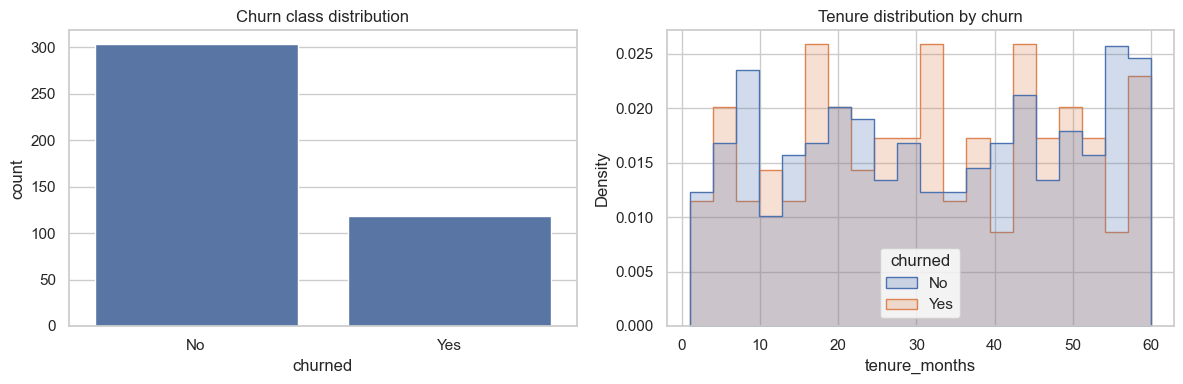

,missing_count
region,129
resolution_median_hours,80
resolution_max_hours,80
ticket_observation_span_days,80
ticket_category_billing,80
ticket_category_bug,80
ticket_category_feature_request,80
resolution_mean_hours,80
ticket_count,80
ticket_category_onboarding,80


In [7]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.countplot(data=churned_labeled, x="churned", ax=axes[0])
axes[0].set_title("Churn class distribution")
sns.histplot(data=features, x="tenure_months", hue="churned", bins=20,
             element="step", stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Tenure distribution by churn")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"eda_overview.png", dpi=180)
plt.show()

display(features.isna().sum().sort_values(ascending=False).head(20).to_frame("missing_count"))

## 6. Build modelling matrices

The positive class (`Yes`) is mapped to 1. The prediction accounts remain separate and are not used during model selection.

In [11]:
labeled = features.dropna(subset=["churned"]).copy()
y = labeled["churned"].map({"No":0, "Yes":1})
if y.isna().any():
    raise ValueError("Unexpected target labels; expected Yes/No.")
y = y.astype(int)
X = labeled.drop(columns=["account_id","churned"])

prediction_frame = features.set_index("account_id").loc[churned_to_predict["account_id"]]
X_predict = prediction_frame.drop(columns=["churned"], errors="ignore").reset_index(drop=True)
X_predict = X_predict.drop(columns=["account_id"], errors="ignore")

print("Labeled accounts:", len(X), "| Prediction accounts:", len(X_predict))
print("Class counts:", y.value_counts().to_dict())

Labeled accounts: 421 | Prediction accounts: 74
Class counts: {0: 303, 1: 118}


## 7. Leakage-safe preprocessing factory

Every fold gets its own preprocessing pipeline. Imputation, MinMax scaling and one-hot encoding are fitted only on that fold's training data. This prevents validation-fold information leaking into preprocessing.

In [12]:
def make_preprocessor(X_part):
    numeric_cols = X_part.select_dtypes(include=["number","bool"]).columns.tolist()
    categorical_cols = [c for c in X_part.columns if c not in numeric_cols]

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", MinMaxScaler())
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_cols),
        ("categorical", categorical_pipe, categorical_cols)
    ], remainder="drop"), numeric_cols, categorical_cols

def build_mlp(input_dim, units=(32,16), dropout=0.25, learning_rate=0.001, l2_value=1e-4):
    model = tf.keras.Sequential([tf.keras.layers.Input(shape=(input_dim,))])
    for i, width in enumerate(units):
        model.add(tf.keras.layers.Dense(
            width, activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(l2_value)
        ))
        if i == 0:
            model.add(tf.keras.layers.BatchNormalization())
        model.add(tf.keras.layers.Dropout(dropout))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name="auc")]
    )
    return model

## 8. Stratified 5-fold out-of-fold evaluation

We generate one OOF probability for every labelled account. Each account is predicted by a model that did not train on that account.

We compare:
- Logistic Regression with balanced class weights.
- A compact MLP with regularization and early stopping.

Because the dataset is small, we keep the network modest to reduce overfitting. Deep learning is not guaranteed to beat the simpler baseline.

In [13]:
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
oof_lr = np.zeros(len(X), dtype=float)
oof_mlp = np.zeros(len(X), dtype=float)
fold_best_epochs = []
fold_rows = []

for fold, (train_idx, valid_idx) in enumerate(skf.split(X, y), start=1):
    print(f"Fold {fold}/{N_SPLITS}")
    X_tr, X_va = X.iloc[train_idx], X.iloc[valid_idx]
    y_tr, y_va = y.iloc[train_idx], y.iloc[valid_idx]

    prep, _, _ = make_preprocessor(X_tr)
    X_tr_p = prep.fit_transform(X_tr).astype("float32")
    X_va_p = prep.transform(X_va).astype("float32")

    # Baseline
    lr = LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5, random_state=SEED)
    lr.fit(X_tr_p, y_tr)
    oof_lr[valid_idx] = lr.predict_proba(X_va_p)[:,1]

    # Neural network: use an inner validation split for early stopping.
    inner_X_tr, inner_X_es, inner_y_tr, inner_y_es = train_test_split(
        X_tr_p, y_tr.to_numpy(), test_size=0.20, random_state=SEED+fold,
        stratify=y_tr.to_numpy()
    )
    fold_classes = np.unique(inner_y_tr)
    fold_weights_arr = compute_class_weight(
        class_weight="balanced", classes=fold_classes, y=inner_y_tr
    )
    fold_weights = {int(c):float(w) for c,w in zip(fold_classes,fold_weights_arr)}

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED+fold)
    nn = build_mlp(X_tr_p.shape[1], units=(32,16), dropout=0.30,
                   learning_rate=0.0007, l2_value=0.001)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=15, min_delta=1e-4, restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=6, min_lr=1e-5
        )
    ]
    hist = nn.fit(
        inner_X_tr, inner_y_tr,
        validation_data=(inner_X_es, inner_y_es),
        epochs=150, batch_size=32, class_weight=fold_weights,
        callbacks=callbacks, verbose=0
    )
    fold_best_epochs.append(int(np.argmin(hist.history["val_loss"])+1))
    oof_mlp[valid_idx] = nn.predict(X_va_p, verbose=0).ravel()

    fold_rows.append({
        "fold":fold,
        "train_rows":len(train_idx),
        "validation_rows":len(valid_idx),
        "best_epoch":fold_best_epochs[-1]
    })

display(pd.DataFrame(fold_rows))
print("OOF predictions generated for", len(y), "accounts.")

Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5


,fold,train_rows,validation_rows,best_epoch
0,1,336,85,1
1,2,337,84,25
2,3,337,84,48
3,4,337,84,12
4,5,337,84,24


OOF predictions generated for 421 accounts.


## 9. Select thresholds from OOF probabilities

Thresholds are selected using OOF predictions, not a single validation set. We report the threshold and the resulting metrics. The threshold is still a data-driven choice and should be recalibrated using business costs and campaign capacity before production use.

In [14]:
def choose_threshold_for_f1(y_true, prob):
    precision, recall, thresholds = precision_recall_curve(y_true, prob)
    if len(thresholds) == 0:
        return 0.5
    f1_vals = 2*precision[:-1]*recall[:-1] / (precision[:-1]+recall[:-1]+1e-12)
    # Keep a broad, practical threshold interval to avoid extreme cutoffs.
    valid = np.where((thresholds >= 0.10) & (thresholds <= 0.90))[0]
    if not len(valid):
        return 0.5
    return float(thresholds[valid[np.argmax(f1_vals[valid])]])

def metrics_at_threshold(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    return {
        "threshold":float(threshold),
        "accuracy":float(accuracy_score(y_true,pred)),
        "precision":float(precision_score(y_true,pred,zero_division=0)),
        "recall":float(recall_score(y_true,pred,zero_division=0)),
        "f1":float(f1_score(y_true,pred,zero_division=0)),
        "roc_auc":float(roc_auc_score(y_true,prob)),
        "pr_auc":float(average_precision_score(y_true,prob))
    }

threshold_lr = choose_threshold_for_f1(y.to_numpy(), oof_lr)
threshold_mlp = choose_threshold_for_f1(y.to_numpy(), oof_mlp)
metrics_lr = metrics_at_threshold(y.to_numpy(), oof_lr, threshold_lr)
metrics_mlp = metrics_at_threshold(y.to_numpy(), oof_mlp, threshold_mlp)

comparison = pd.DataFrame([
    {"model":"Logistic Regression", **metrics_lr},
    {"model":"Deep Learning MLP", **metrics_mlp}
]).set_index("model")
display(comparison.round(4))

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
Logistic Regression,0.4786,0.6508,0.4249,0.6949,0.5273,0.7166,0.5142
Deep Learning MLP,0.4239,0.6033,0.3828,0.6780,0.4893,0.6495,0.4051


## 10. OOF classification reports and confusion matrices

LOGISTIC REGRESSION — OOF
              precision    recall  f1-score   support

    No churn       0.84      0.63      0.72       303
       Churn       0.42      0.69      0.53       118

    accuracy                           0.65       421
   macro avg       0.63      0.66      0.63       421
weighted avg       0.73      0.65      0.67       421

DEEP LEARNING MLP — OOF
              precision    recall  f1-score   support

    No churn       0.82      0.57      0.68       303
       Churn       0.38      0.68      0.49       118

    accuracy                           0.60       421
   macro avg       0.60      0.63      0.58       421
weighted avg       0.70      0.60      0.62       421



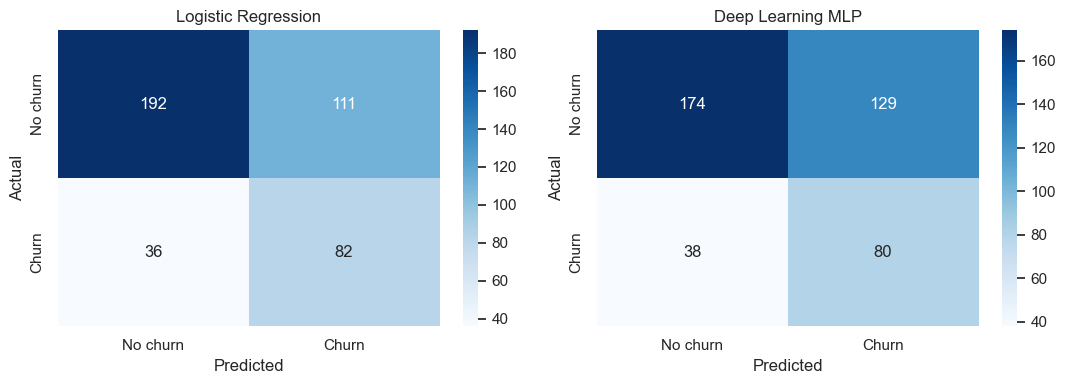

In [15]:
pred_lr = (oof_lr >= threshold_lr).astype(int)
pred_mlp = (oof_mlp >= threshold_mlp).astype(int)

print("LOGISTIC REGRESSION — OOF")
print(classification_report(y, pred_lr, target_names=["No churn","Churn"], zero_division=0))
print("DEEP LEARNING MLP — OOF")
print(classification_report(y, pred_mlp, target_names=["No churn","Churn"], zero_division=0))

fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax, title, pred in [
    (axes[0],"Logistic Regression",pred_lr),
    (axes[1],"Deep Learning MLP",pred_mlp)
]:
    sns.heatmap(confusion_matrix(y,pred),annot=True,fmt="d",cmap="Blues",
                xticklabels=["No churn","Churn"],yticklabels=["No churn","Churn"],ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"oof_confusion_matrices.png",dpi=180)
plt.show()

## 11. OOF ROC and Precision–Recall curves

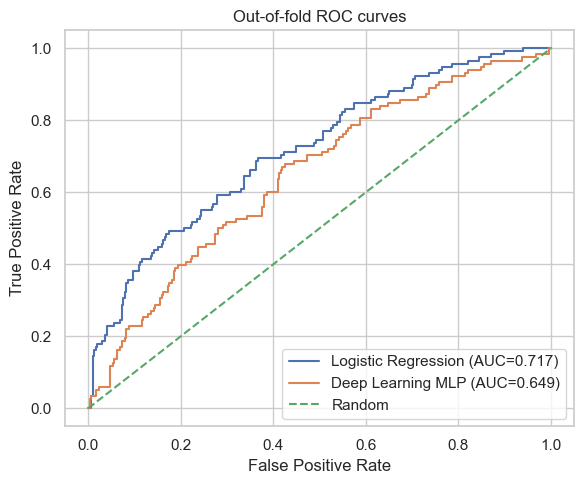

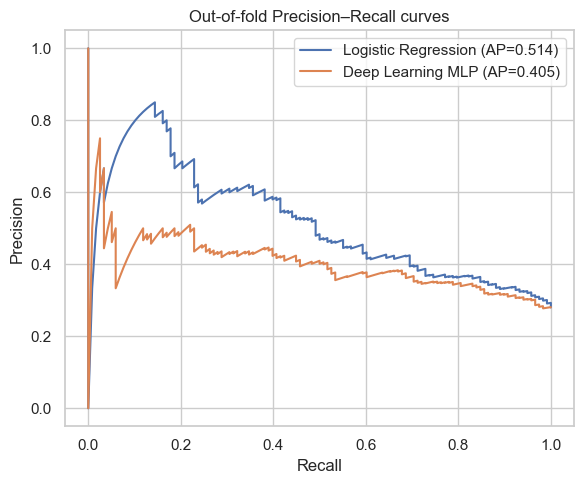

In [16]:
fig, ax = plt.subplots(figsize=(6,5))
for name, prob in [("Logistic Regression",oof_lr),("Deep Learning MLP",oof_mlp)]:
    fpr,tpr,_ = roc_curve(y,prob)
    ax.plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(y,prob):.3f})")
ax.plot([0,1],[0,1],"--",label="Random")
ax.set(title="Out-of-fold ROC curves",xlabel="False Positive Rate",ylabel="True Positive Rate")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"oof_roc_curves.png",dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(6,5))
for name, prob in [("Logistic Regression",oof_lr),("Deep Learning MLP",oof_mlp)]:
    precision,recall,_ = precision_recall_curve(y,prob)
    ax.plot(recall,precision,label=f"{name} (AP={average_precision_score(y,prob):.3f})")
ax.set(title="Out-of-fold Precision–Recall curves",xlabel="Recall",ylabel="Precision")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"oof_precision_recall_curves.png",dpi=180)
plt.show()

## 12. Choose a model transparently

The notebook uses F1 as a neutral starting point for threshold selection, but the business may prefer higher precision (fewer unnecessary retention contacts) or higher recall (miss fewer churners).

We choose the final candidate by OOF F1 here. If the scores are close, prefer the simpler Logistic Regression model unless the MLP provides a meaningful, repeatable gain. Review the comparison table before accepting the selected model.

In [17]:
candidate_scores = {
    "Logistic Regression": metrics_lr["f1"],
    "Deep Learning MLP": metrics_mlp["f1"]
}
selected_model_name = max(candidate_scores, key=candidate_scores.get)
print("OOF F1-based candidate:", selected_model_name)
print("Note: inspect the full metric table and business trade-offs before final sign-off.")

OOF F1-based candidate: Logistic Regression
Note: inspect the full metric table and business trade-offs before final sign-off.


## 13. Fit final preprocessing and models on all labelled data

After cross-validation comparison, fit the final preprocessing pipeline on all labelled accounts. Save both a Logistic Regression and an MLP model so the selected candidate can be retained and the alternative remains available for audit.

For the final MLP epoch count, use the median best epoch across folds rather than selecting an arbitrary maximum.

In [18]:
final_preprocessor, final_numeric_cols, final_categorical_cols = make_preprocessor(X)
X_all = final_preprocessor.fit_transform(X).astype("float32")
X_unseen = final_preprocessor.transform(X_predict).astype("float32")

final_lr = LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5, random_state=SEED)
final_lr.fit(X_all,y)

final_epochs = max(10, int(np.median(fold_best_epochs)))
final_classes = np.unique(y)
final_weights_arr = compute_class_weight(class_weight="balanced",classes=final_classes,y=y)
final_weights = {int(c):float(w) for c,w in zip(final_classes,final_weights_arr)}

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
final_mlp = build_mlp(X_all.shape[1], units=(32,16), dropout=0.30,
                      learning_rate=0.0007, l2_value=0.001)
final_mlp.fit(
    X_all,y.to_numpy(),epochs=final_epochs,batch_size=32,
    class_weight=final_weights,verbose=0
)

print("Final MLP epochs:",final_epochs)

Final MLP epochs: 24


## 14. Generate final predictions for the 74 requested accounts

In [19]:
# Generate probabilities from both candidates.
prob_lr_final = final_lr.predict_proba(X_unseen)[:,1]
prob_mlp_final = final_mlp.predict(X_unseen,verbose=0).ravel()

if selected_model_name == "Deep Learning MLP":
    selected_prob = prob_mlp_final
    selected_threshold = threshold_mlp
else:
    selected_prob = prob_lr_final
    selected_threshold = threshold_lr

final_predictions = churned_to_predict[["account_id"]].copy()
final_predictions["churn_probability"] = selected_prob
final_predictions["predicted_churned"] = np.where(selected_prob >= selected_threshold,"Yes","No")
final_predictions["selected_model"] = selected_model_name
final_predictions.to_csv(OUTPUT_DIR/"final_predictions.csv",index=False)

display(final_predictions.head(10))
print("Predictions:",len(final_predictions)," | Expected:",len(churned_to_predict))
assert len(final_predictions)==len(churned_to_predict)

,account_id,churn_probability,predicted_churned,selected_model
0,CUST-0005,0.355030,No,Logistic Regression
1,CUST-0021,0.482692,Yes,Logistic Regression
2,CUST-0027,0.918162,Yes,Logistic Regression
3,CUST-0028,0.321585,No,Logistic Regression
4,CUST-0033,0.429874,No,Logistic Regression
5,CUST-0047,0.403070,No,Logistic Regression
6,CUST-0048,0.380709,No,Logistic Regression
7,CUST-0052,0.896869,Yes,Logistic Regression
8,CUST-0063,0.815973,Yes,Logistic Regression
9,CUST-0066,0.635691,Yes,Logistic Regression


Predictions: 74  | Expected: 74


## 15. Save metrics, preprocessing and trained models

In [20]:
results = {
    "evaluation_method":"Stratified 5-fold out-of-fold predictions",
    "random_state":SEED,
    "labelled_accounts":int(len(X)),
    "prediction_accounts":int(len(X_predict)),
    "class_distribution":{"No":int((y==0).sum()),"Yes":int((y==1).sum())},
    "logistic_regression_oof":metrics_lr,
    "deep_learning_mlp_oof":metrics_mlp,
    "selected_candidate_by_oof_f1":selected_model_name,
    "final_mlp_epochs":final_epochs,
    "fold_best_epochs":fold_best_epochs
}
with open(OUTPUT_DIR/"optimized_validation_metrics.json","w",encoding="utf-8") as f:
    json.dump(results,f,indent=4)

joblib.dump(final_preprocessor,MODEL_DIR/"final_preprocessor.joblib")
joblib.dump(final_lr,MODEL_DIR/"final_logistic_regression.joblib")
final_mlp.save(MODEL_DIR/"final_mlp.keras")

with open(OUTPUT_DIR/"optimized_classification_reports.txt","w",encoding="utf-8") as f:
    f.write("LOGISTIC REGRESSION — OOF\\n")
    f.write(classification_report(y,pred_lr,target_names=["No churn","Churn"],zero_division=0))
    f.write("\\nDEEP LEARNING MLP — OOF\\n")
    f.write(classification_report(y,pred_mlp,target_names=["No churn","Churn"],zero_division=0))

print("Saved metrics, reports, preprocessing pipeline and models.")

Saved metrics, reports, preprocessing pipeline and models.


## 16. Optional: SHAP explainability

SHAP is intentionally optional because it adds a dependency and can be computationally expensive. For a small tabular dataset, permutation importance is a practical first explanation method. The code below evaluates feature importance for the selected model using the fitted full-data pipeline; it is descriptive, not causal.

For this notebook, we calculate permutation importance for the Logistic Regression model only when selected. If MLP is selected, explainability can be added as a separate, model-specific step after verifying package compatibility.

In [21]:
from sklearn.inspection import permutation_importance

# Use a small stratified holdout only for a diagnostic feature-importance view.
X_imp_train, X_imp_val, y_imp_train, y_imp_val = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
imp_preprocessor, _, _ = make_preprocessor(X_imp_train)
X_imp_train_p = imp_preprocessor.fit_transform(X_imp_train)
X_imp_val_p = imp_preprocessor.transform(X_imp_val)
imp_model = LogisticRegression(max_iter=3000,class_weight="balanced",C=0.5,random_state=SEED)
imp_model.fit(X_imp_train_p,y_imp_train)

# Permutation importance on transformed columns is available; use ROC-AUC scoring.
perm = permutation_importance(
    imp_model,X_imp_val_p,y_imp_val,n_repeats=10,random_state=SEED,scoring="roc_auc"
)
importance = pd.DataFrame({
    "transformed_feature":np.arange(len(perm.importances_mean)),
    "importance_mean":perm.importances_mean,
    "importance_std":perm.importances_std
}).sort_values("importance_mean",ascending=False)
display(importance.head(15))

,transformed_feature,importance_mean,importance_std
3,3,0.015779,0.016471
11,11,0.015301,0.014188
9,9,0.010792,0.014716
7,7,0.009016,0.017334
2,2,0.007719,0.011344
15,15,0.007036,0.004288
6,6,0.006352,0.013959
36,36,0.005123,0.002165
32,32,0.004713,0.003339
30,30,0.004713,0.007251


## 17. Final interpretation and limitations

- The OOF metrics are more informative than a single random split, but 421 labels still produce uncertainty.
- Repeated CV or an external time-based test set would provide stronger evidence if more labeled history becomes available.
- Aggregated usage/ticket features use the supplied history as provided. If records include activity after the churn prediction cutoff, that would create temporal leakage; the dataset does not specify an explicit cutoff date, so this assumption must be checked with the data owner.
- Thresholds are chosen by OOF F1, not by profit or retention-team capacity.
- Model scores do not prove that a feature causes churn.
- Do not claim a model is better unless the generated OOF metrics support that conclusion.

### Main outputs
- `outputs/account_features.csv`
- `outputs/optimized_validation_metrics.json`
- `outputs/optimized_classification_reports.txt`
- `outputs/oof_confusion_matrices.png`
- `outputs/oof_roc_curves.png`
- `outputs/oof_precision_recall_curves.png`
- `outputs/final_predictions.csv`
- `models/final_preprocessor.joblib`
- `models/final_logistic_regression.joblib`
- `models/final_mlp.keras`

### Conclusion

This project successfully demonstrated the application of Machine Learning and Deep Learning techniques for predicting customer churn in a SaaS environment. By combining customer account information, usage activity, and support-ticket data, meaningful customer-level features were developed for classification.

A Feedforward Neural Network (MLP) was implemented using TensorFlow/Keras and compared with a Balanced Logistic Regression model using Stratified 5-Fold Cross-Validation. Based on the evaluation results, Logistic Regression achieved better overall performance than the Deep Learning model in this experiment, with an F1-score of 52.73% compared to 48.93%.

The selected model was then used to generate churn predictions for 74 customer accounts. This project provided practical experience in data preprocessing, feature engineering, model development, cross-validation, performance evaluation, and model selection.

Overall, the project highlights how data-driven predictive models can help SaaS businesses identify customers who may be at risk of leaving and support proactive customer retention strategies.
